# Task 2 — Gestalt principles of grouping

The data are almost the same in every panel; the grouping is created by placement, boundary, connection, and similarity. The perception comes from arrangement, not from the numbers.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Rectangle

base = Path('data')
gestalt = pd.read_csv(base / 'stimuli_gestalt.csv')
print(gestalt.head())

       panel group       x       y colour   shape  size connector
0  proximity    g0  1.5130  1.6220   grey  circle    60      none
1  proximity    g0  1.2277  0.8682   grey  circle    60      none
2  proximity    g0  0.8520  0.0809   grey  circle    60      none
3  proximity    g0  0.6835  0.9270   grey  circle    60      none
4  proximity    g0  0.4485  1.3725   grey  circle    60      none


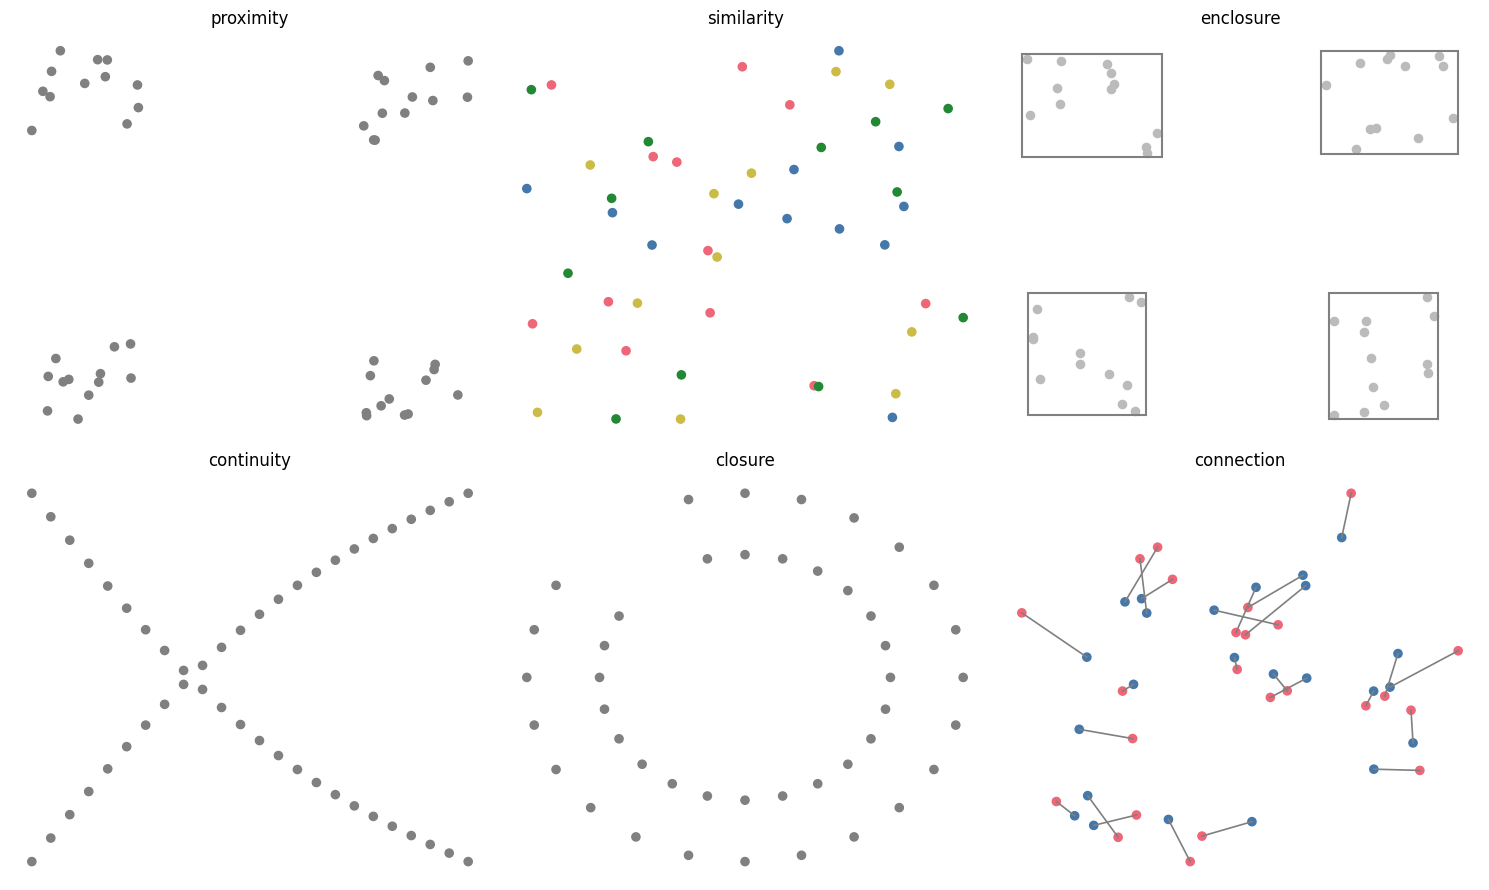

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for ax, panel in zip(axes, ['proximity', 'similarity', 'enclosure', 'continuity', 'closure', 'connection']):
    d = gestalt[gestalt['panel'] == panel]
    if panel == 'enclosure':
        for g in sorted(d['group'].unique()):
            sub = d[d['group'] == g]
            ax.scatter(sub['x'], sub['y'], color='#bbb', s=35)
            xmin, xmax = sub['x'].min(), sub['x'].max()
            ymin, ymax = sub['y'].min(), sub['y'].max()
            ax.add_patch(Rectangle((xmin - 0.08, ymin - 0.08), (xmax - xmin) + 0.16, (ymax - ymin) + 0.16, fill=False, edgecolor='gray', lw=1.5))
    elif panel == 'connection':
        for key, grp in d.groupby('connector'):
            if key == 'none':
                continue
            sub = grp.sort_values('x')
            if len(sub) == 2:
                ax.plot(sub['x'], sub['y'], color='gray', linewidth=1.2)
                ax.scatter(sub['x'], sub['y'], color=sub['colour'].tolist(), s=35)
    else:
        ax.scatter(d['x'], d['y'], color=d['colour'], s=35)
    ax.set_title(panel)
    ax.axis('off')
fig.tight_layout()

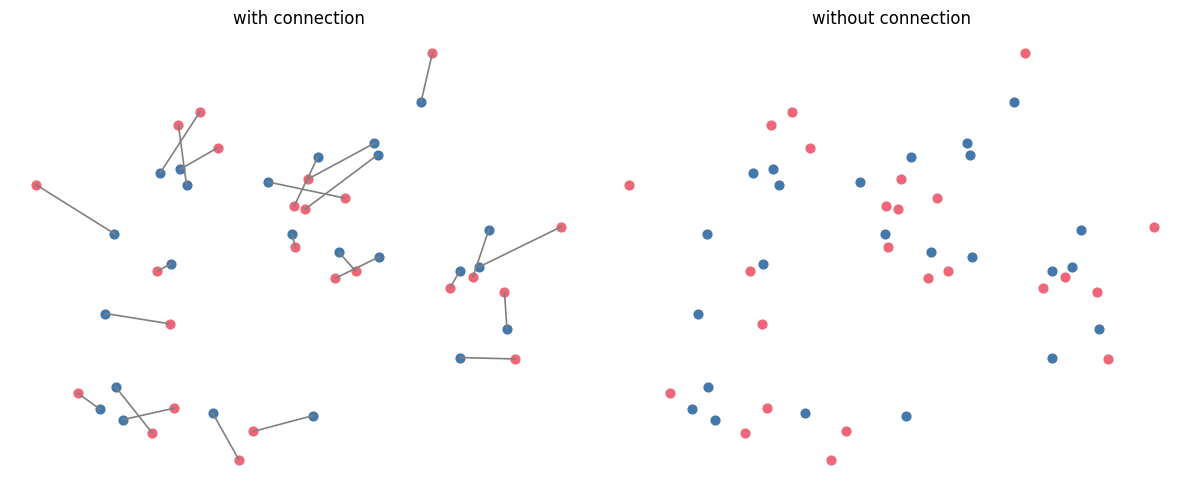

In [3]:
# Connection vs proximity/similarity fight
conn = gestalt[gestalt['panel'] == 'connection'].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, with_line in zip(axes, [True, False]):
    d = conn.copy()
    if with_line:
        for key, grp in d.groupby('connector'):
            if key == 'none':
                continue
            sub = grp.sort_values('x')
            ax.plot(sub['x'], sub['y'], color='gray', linewidth=1.2)
    for _, row in d.iterrows():
        ax.scatter(row['x'], row['y'], color=row['colour'], s=40)
    ax.set_title('with connection' if with_line else 'without connection')
    ax.axis('off')
fig.tight_layout()

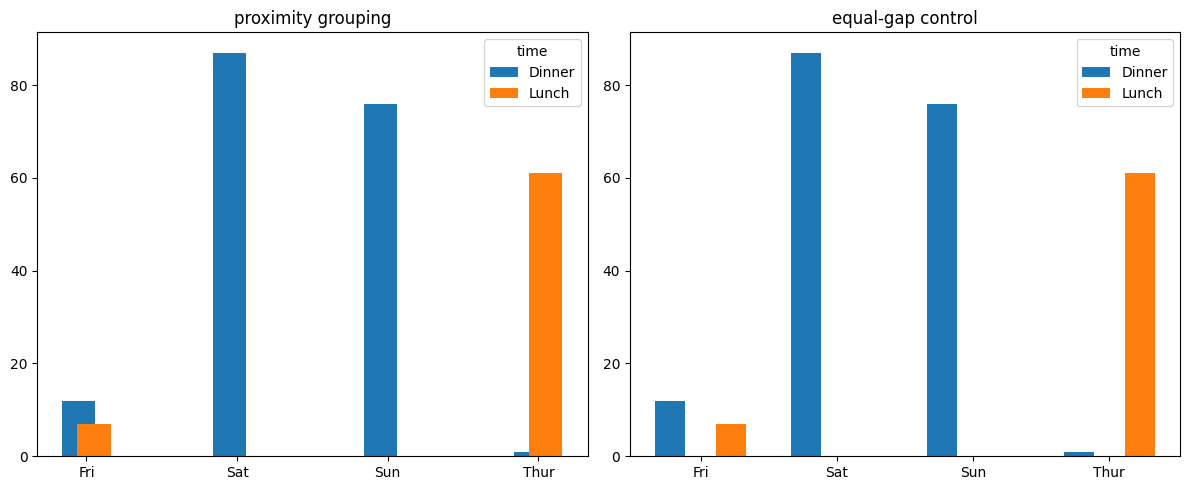

In [4]:
tips = pd.read_csv(base / 'tips.csv')
by_day_time = tips.groupby(['day', 'time']).size().unstack(fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, gap in zip(axes, [0.1, 0.45]):
    pos = np.arange(len(by_day_time.index))
    for i, col in enumerate(by_day_time.columns):
        vals = by_day_time[col].to_numpy()
        offset = (i - (len(by_day_time.columns)-1)/2) * gap
        ax.bar(pos + offset, vals, width=0.22, label=col)
    ax.set_xticks(pos)
    ax.set_xticklabels(by_day_time.index)
    ax.set_title('proximity grouping' if gap < 0.2 else 'equal-gap control')
    ax.legend(title='time')
fig.tight_layout()

In [5]:
# Interpretation
# Proximity is the strongest grouping force in the chart because the within-group spacing is made smaller than the between-group spacing. When the gaps are equalised, the groups stop reading as natural units, even though the underlying numbers are unchanged.
# In direct labelling, the eye does not have to hold a colour in working memory and match it to a legend: the label sits next to the data and uses proximity to attach text and mark. That is cheaper than a separate legend because it reduces decoding effort and working-memory load.